# Presentation figures

Every figure for the deck, drawn from the analysis notebooks' written outputs at slide size in one style, and exported as vector PDF and 300 dpi PNG with no title or caption inside the image. The text for each figure (title, caption, narration line, and the numbers the figure used) is written beside it as JSON and collected into one `slide_text.json`, so all slide text is edited in the slide software.

**Run order.** The analysis notebooks must have run first; the check below lists any missing table. Nothing here reruns an analysis.

**Conventions.** 2023 in grey-blue, 2024 in magenta, everything else in greys; filled markers clear the null, hollow markers lean; sizes are physical inches on a 16:9 slide (`presentation.style.SIZES`), so text is at slide point size and the image is placed without scaling. Code in `scripts/presentation/`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys, json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("scripts").resolve()))

from common.config import load_settings
from presentation import figures as pf
from presentation import style as st
from presentation.text_registry import TEXT

settings = load_settings()
OUTPUTS = settings.outputs_dir
DEST = settings.output_dir("presentation")
EARLIER, LATER = settings.earlier_season, settings.later_season
SESOI_PER_BALL = float(settings.section("sesoi")["expected_wickets_per_ball"])
print(f"outputs={OUTPUTS}  destination={DEST}")

outputs=/Users/madkad/dpl_2026_s1/outputs  destination=/Users/madkad/dpl_2026_s1/outputs/presentation


## Are the inputs there?

The tables each figure reads, and whether they exist.

In [2]:
REQUIRED = {
    "mean_level_and_tail": ["theme_contrasts"],
    "run_rate_mechanics": ["run_rate_decomposition"],
    "expected_wickets": ["powerplay_contrast", "fixed_vs_refit_intervals", "shot_level_rung"],
    "win_probability_ledger": ["powerplay_ledger", "powerplay_aggression"],
    "powerplay_risk_ledger": ["per_team_season_ledger"],
    "bowling_response": ["delivery_menu", "shift_share_components"],
    "spin_displacement": ["spin_share_decomposition"],
    "batter_continuity": ["powerplay_six_rate_components", "composition_by_auction_route"],
    "impact_substitute_mechanics": ["chase_target_response", "chase_target_response_middle_death",
                                    "deployments_by_side_innings", "substitute_contribution_summary"],
}
missing = [f"{a}/{n}.csv" for a, names in REQUIRED.items() for n in names if not (OUTPUTS / a / f"{n}.csv").exists()]
print("all inputs present" if not missing else "missing:\n  " + "\n  ".join(missing))

all inputs present


## Build and export

One cell per slide. Each figure is shown here with its title for review; the export drops the title and writes the text JSON.

In [3]:
slide_text = {}

def build(name, fig, numbers):
    entry = st.export(fig, name, DEST, text={**TEXT[name], "numbers": numbers}, title=TEXT[name]["title"])
    slide_text[name] = entry
    plt.show()
    return entry

### Performance overview

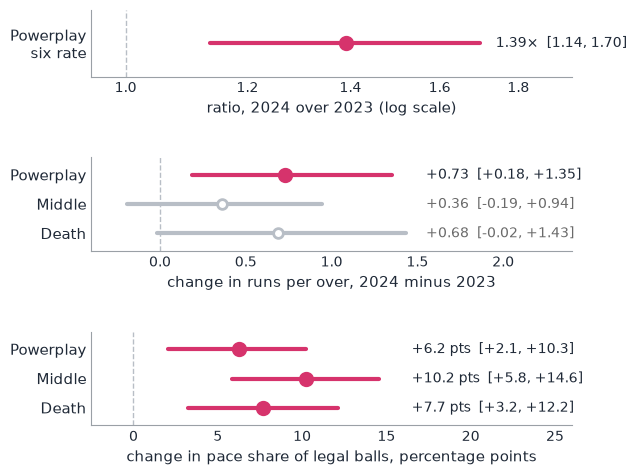

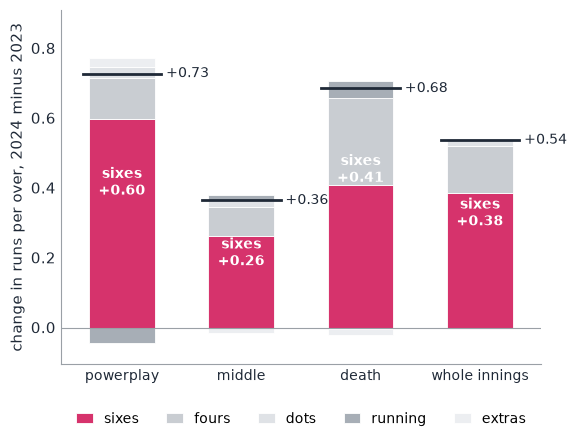

{'figure': 'run_rate_mechanism',
 'title': 'Where the extra runs came from: sixes, and almost nothing else',
 'caption': 'Exact Shapley attribution of the run-rate change to fours, sixes, dots, running and extras; the parts sum to the total on every match resample. All innings.',
 'narration': 'In the powerplay, three quarters of the rise is more boundaries and a quarter is boundaries becoming sixes. Dots, running and extras did not move in any phase.',
 'numbers': {'totals': {'powerplay': 0.7278831720481627,
   'middle': 0.3641935476731284,
   'death': 0.6849480291803811,
   'whole_innings': 0.5370156276470492},
  'sixes': {'powerplay': 0.5972742931709683,
   'middle': 0.2619968874136524,
   'death': 0.4075652150834146,
   'whole_innings': 0.3849029500532852}}}

In [4]:
fig, n = pf.season_contrasts_forest(OUTPUTS, EARLIER, LATER, title=TEXT["season_contrasts_forest"]["title"]); build("season_contrasts_forest", fig, n)
fig, n = pf.run_rate_mechanism(OUTPUTS, EARLIER, LATER, title=TEXT["run_rate_mechanism"]["title"]); build("run_rate_mechanism", fig, n)

### The headline priced

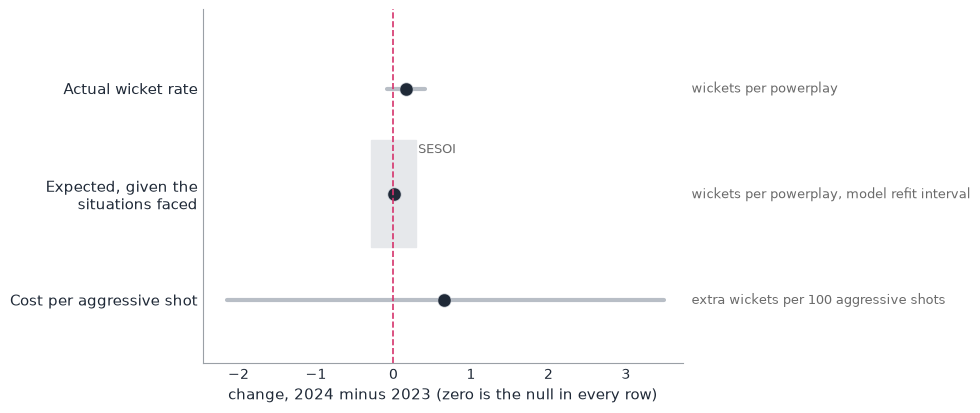

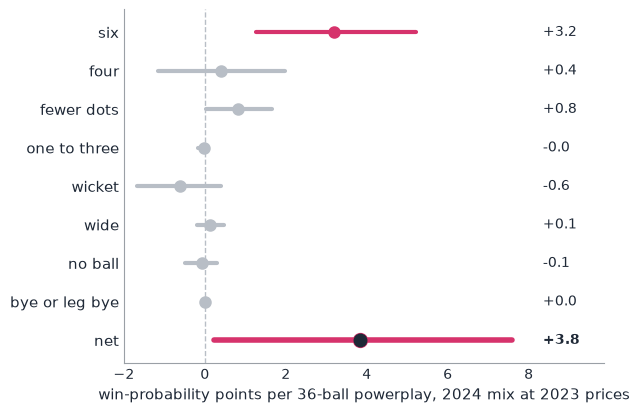

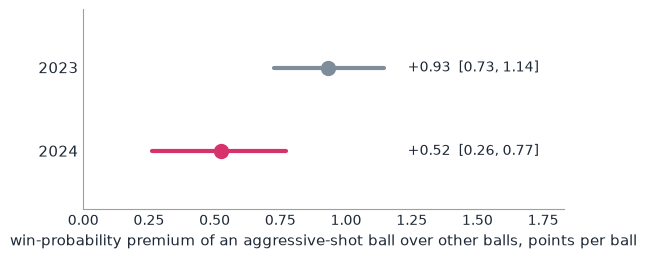

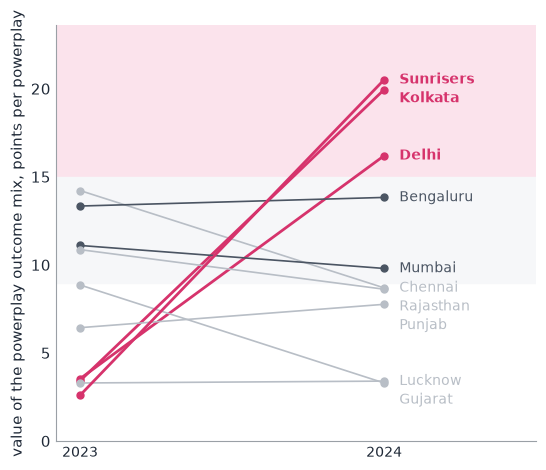

{'figure': 'team_value_slope',
 'title': 'Who took the risk: three teams, and the order reversed',
 'caption': 'Value of the powerplay outcome mix per team-season, points per powerplay at pooled prices, means over about fourteen powerplays; read as tiers.',
 'narration': 'Sunrisers, Kolkata and Delhi attacked most and bought two to three times the value of the five teams that attacked least, paying a wicket cost no different from what their situations predicted.',
 'numbers': {'Chennai': {'2023': 14.233668746775546,
   '2024': 8.706923321782332},
  'Delhi': {'2023': 3.5475899576420553, '2024': 16.21051790681619},
  'Gujarat': {'2023': 8.87296328754449, '2024': 3.308074437048641},
  'Kolkata': {'2023': 3.4324693502594563, '2024': 19.962958445773864},
  'Lucknow': {'2023': 3.3075257720609126, '2024': 3.4139171923704743},
  'Mumbai': {'2023': 11.115247875949995, '2024': 9.810398104620967},
  'Punjab': {'2023': 6.447587436976618, '2024': 7.773961802304621},
  'Rajasthan': {'2023': 10.87855

In [5]:
fig, n = pf.wicket_cost_three_levels(OUTPUTS, EARLIER, LATER, SESOI_PER_BALL, title=TEXT["wicket_cost_three_levels"]["title"]); build("wicket_cost_three_levels", fig, n)
fig, n = pf.powerplay_ledger(OUTPUTS, EARLIER, LATER, title=TEXT["powerplay_ledger"]["title"]); build("powerplay_ledger", fig, n)
fig, n = pf.aggression_premium(OUTPUTS, EARLIER, LATER, title=TEXT["aggression_premium"]["title"]); build("aggression_premium", fig, n)
fig, n = pf.team_value_slope(OUTPUTS, EARLIER, LATER, title=TEXT["team_value_slope"]["title"]); build("team_value_slope", fig, n)

### The bowling side

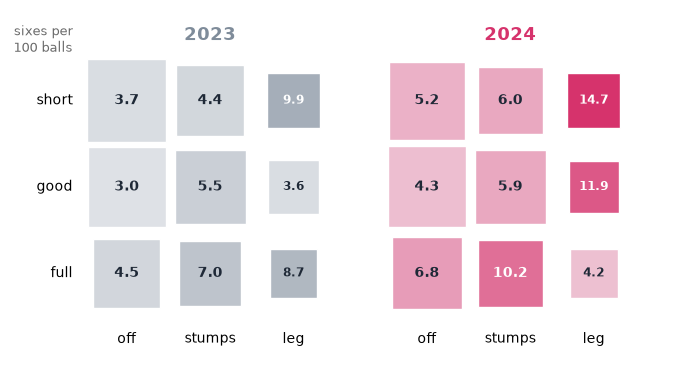

within 97% of the change, mix 3%


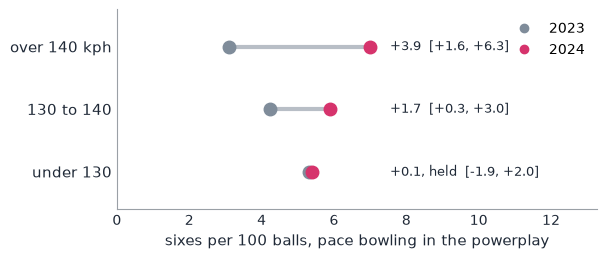

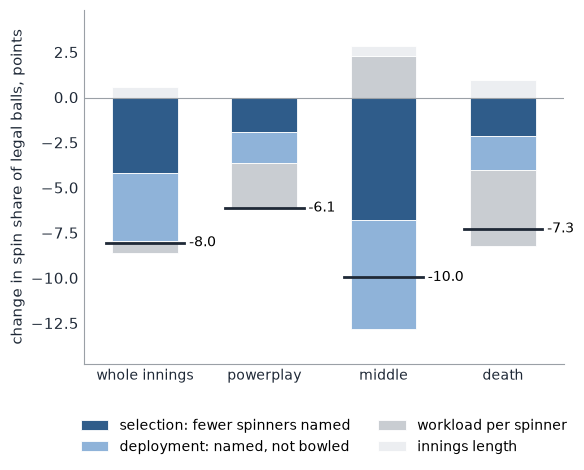

{'figure': 'spin_decomposition',
 'title': 'Spin was picked less and benched more; squads and workload unchanged',
 'caption': 'Change in the spin share of legal balls, percentage points, attributed exactly to selection (spinners named per eleven), deployment (share of named spinners who bowled), workload (balls per spinner who bowled) and innings length, under the match bootstrap.',
 'narration': 'Teams kept and bought spinners as before, named a third of a spinner fewer per eleven and bowled fewer of the ones they named; the middle overs were a headcount story.',
 'numbers': {'totals': {'whole innings': -8.033245368556818,
   'powerplay': -6.1118030936944425,
   'middle': -9.953881577963386,
   'death': -7.26887805858189}}}

In [6]:
fig, n = pf.line_length_grid(OUTPUTS, EARLIER, LATER, title=TEXT["line_length_grid"]["title"]); entry = build("line_length_grid", fig, n)
print(f"within {100 * n['within_share']:.0f}% of the change, mix {100 * n['mix_share']:.0f}%")
fig, n = pf.speed_bands(OUTPUTS, EARLIER, LATER, title=TEXT["speed_bands"]["title"]); build("speed_bands", fig, n)
fig, n = pf.spin_decomposition(OUTPUTS, title=TEXT["spin_decomposition"]["title"]); build("spin_decomposition", fig, n)

### Who and how

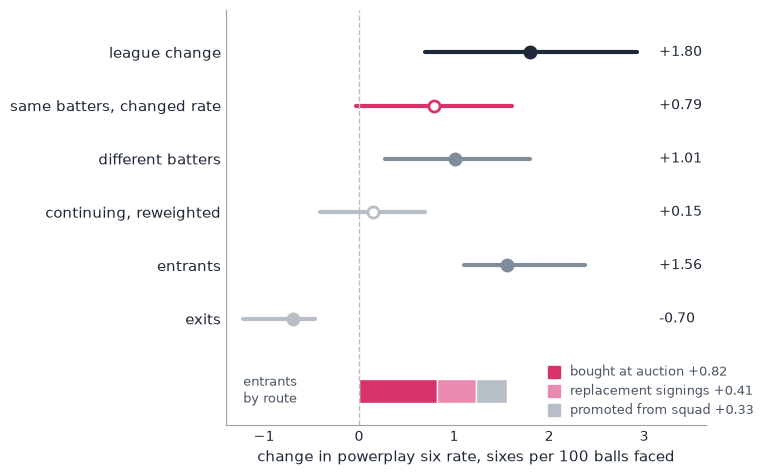

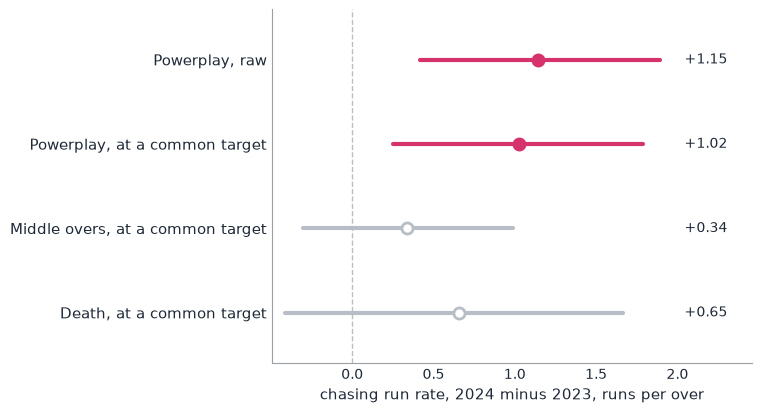

{
 "bowling_first_first_innings": {
  "2023": 17,
  "2024": 17
 },
 "batting_first_first_innings": {
  "2023": 9,
  "2024": 26
 },
 "substitute_contribution": {
  "2023": {
   "swaps": 9,
   "sub_batted_share": 1.0,
   "sub_strike_rate": 101.78571428571428,
   "others_strike_rate": 111.6751269035533
  },
  "2024": {
   "swaps": 26,
   "sub_batted_share": 0.7692307692307693,
   "sub_strike_rate": 112.5,
   "others_strike_rate": 133.72781065088756
  }
 }
}


In [9]:
fig, n = pf.batter_decomposition(OUTPUTS, EARLIER, LATER, title=TEXT["batter_decomposition"]["title"]); build("batter_decomposition", fig, n)
fig, n = pf.chase_target(OUTPUTS, EARLIER, LATER, title=TEXT["chase_target"]["title"]); build("chase_target", fig, n)
slide_text["substitute_numbers"] = {**TEXT["substitute_numbers"], "numbers": pf.substitute_numbers(OUTPUTS, EARLIER, LATER)}
print(json.dumps(slide_text["substitute_numbers"]["numbers"], indent=1))

## Slide text

Every figure's title, caption, narration line and numbers in one file, plus the exported file list.

In [8]:
(DEST / "slide_text.json").write_text(json.dumps(slide_text, indent=2))
files = sorted(p.name for p in DEST.iterdir() if p.suffix in (".pdf", ".png"))
print(f"{len(files)} image files in {DEST}")
pd.DataFrame([{"figure": k, "title": v["title"], "caption": v["caption"]} for k, v in slide_text.items()])

22 image files in /Users/madkad/dpl_2026_s1/outputs/presentation


,figure,title,caption
0,season_contrasts_forest,"What changed between the seasons, with intervals","Match cluster bootstrap on the same 10,000 mat..."
1,run_rate_mechanism,"Where the extra runs came from: sixes, and alm...",Exact Shapley attribution of the run-rate chan...
2,wicket_cost_three_levels,"No wicket cost, at three levels of accounting","Change 2024 minus 2023, zero the common null. ..."
3,powerplay_ledger,"What the 2024 powerplay mix was worth, at 2023...",Each outcome priced as the mean change in the ...
4,aggression_premium,Diminishing returns: each aggressive shot boug...,Mean change in win probability on aggressive-s...
5,team_value_slope,"Who took the risk: three teams, and the order ...",Value of the powerplay outcome mix per team-se...
6,line_length_grid,"Menu, not mix: every class of delivery was hit...",Powerplay sixes per 100 legal balls by line an...
7,speed_bands,"Pace was the target; the slower ball held, and...",Pace deliveries in the powerplay by tracked sp...
8,spin_decomposition,Spin was picked less and benched more; squads ...,"Change in the spin share of legal balls, perce..."
9,batter_decomposition,Half the rise was three openers; most of the o...,Exact decomposition of the powerplay six-rate ...
